In [6]:
# load the comments
import pandas as pd

url = "https://raw.githubusercontent.com/macss-berkeley/compss-211a/main/docs/interactives/data/week08/aita_replies.csv"
comments = pd.read_csv(url)

In [7]:
# take the verdict from the first word, keep the comments with NTA or YTA
comments["verdict"] = comments["body"].str.upper().str.extract(r"^(NTA|YTA)\b")[0]
comments = comments.dropna(subset=["verdict"]).reset_index(drop=True)
len(comments)  # 1035

1035

In [8]:
# remove every verdict word from the text
verdict_words = r"\b(NTA|YTA|ESH|NAH|INFO)\b"
comments["text"] = comments["body"].str.replace(verdict_words, "", regex=True, case=False)
comments["text"] = comments["text"].str.lstrip(" .,:;!-–—")

In [9]:
# the three example comments from the slides
examples = [204, 232, 75]  # the three comments on the slides
comments.loc[examples, ["verdict", "text"]]

,verdict,text
204,NTA,He needed to know - otherwise he's left thinki...
232,NTA,at all. She is taking advantage of you and adm...
75,YTA,"because this is exactly what you agreed to, bu..."


## TF-IDF

In [3]:
# make the TF-IDF table: one row per comment, one column per word
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words="english", min_df=15)  # words in at least 15 comments
weights = pd.DataFrame(tfidf.fit_transform(comments["text"]).toarray(),
                       columns=tfidf.get_feature_names_out())
weights.shape  # (1035, 220)

(1035, 220)

In [4]:
# the weights of six words for the three example comments
weights.loc[examples, ["thinking", "bad", "know", "taking", "stay", "job"]].round(2)

,thinking,bad,know,taking,stay,job
204,0.69,0.55,0.47,0.00,0.0,0.00
232,0.00,0.00,0.00,0.58,0.6,0.00
75,0.40,0.00,0.00,0.00,0.0,0.34


In [5]:
# average the rows for each verdict, then divide the YTA average by the NTA average
by_verdict = weights.groupby(comments["verdict"]).mean().T
by_verdict["ratio"] = by_verdict["YTA"] / by_verdict["NTA"]
by_verdict.sort_values("ratio")

verdict,NTA,YTA,ratio
behavior,0.014858,0.000000,0.000000
respect,0.011282,0.002944,0.260979
able,0.007855,0.002383,0.303383
change,0.010500,0.003215,0.306210
won,0.010508,0.003226,0.307000
...,...,...,...
dude,0.004801,0.016045,3.342124
world,0.002500,0.009836,3.934081
knew,0.002974,0.011789,3.963874
look,0.003178,0.014314,4.504456


<Axes: xlabel='average TF-IDF weight'>

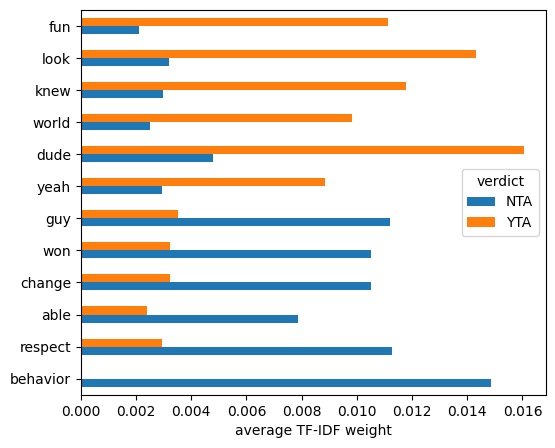

In [10]:
# plot the 6 most NTA-like and the 6 most YTA-like words
by_ratio = by_verdict.sort_values("ratio")
selected = pd.concat([by_ratio.head(6), by_ratio.tail(6)])
selected[["NTA", "YTA"]].plot.barh(figsize=(6, 5), xlabel="average TF-IDF weight", ylabel="")

## Embeddings

In [11]:
# turn every comment into 384 numbers
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")  # downloads about 90 MB the first time
embeddings = model.encode(comments["text"].tolist(), normalize_embeddings=True)
embeddings.shape  # (1035, 384)

/Users/tomvannuenen/Library/CloudStorage/Dropbox/GitHub/DEV/compss-211a/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(1035, 384)

In [12]:
# the first 4 of the 384 numbers for the three example comments
pd.DataFrame(embeddings[examples, :4], index=examples).round(2)

,0,1,2,3
204,0.04,-0.07,0.02,0.08
232,0.08,0.08,0.01,-0.03
75,-0.08,0.05,0.04,0.02


In [13]:
# find the comments closest to a sentence
query = model.encode(["Your partner is controlling you."], normalize_embeddings=True)[0]
comments["similarity"] = embeddings @ query  # how close each comment is to the sentence
comments.sort_values("similarity", ascending=False).head(4)[["similarity", "verdict", "text"]]

,similarity,verdict,text
545,0.568036,YTA,no doubt. And you’re incredibly controlling. I...
36,0.490679,NTA,your girlfriend is disregarding your discomfor...
353,0.474700,NTA,your GF has some insecurity/trust issues or so...
194,0.461813,NTA,\n\nShe sounds like the extremely jealous/cont...


## An LLM label

Needs `GEMINI_API_KEY` in your `.env` file. 12 calls.

In [14]:
# connect to gemini with the key from your .env file
import os

from dotenv import load_dotenv
from google import genai

load_dotenv()
client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [15]:
# ask gemini whether each example comment says the poster was wrong
question = ("Does this comment say the poster was in the wrong? "
            "Answer yes or no, then give a one-sentence reason.")

def label(text):
    response = client.models.generate_content(model="gemini-3.5-flash-lite",
                                              contents=question + "\n\nComment: " + text)
    return response.text

comments.loc[examples, "text"].map(label)  # 3 comments, 3 calls

204    Yes. \n\nThe comment justifies and defends the...
232    No. The comment places the blame entirely on t...
75     Yes. \n\nThe poster states that the parent agr...
Name: text, dtype: object

In [ ]:
# ask about three borderline comments three times each; keep only the yes or no
borderline = comments.index[comments["idstr"].isin(["t1_ehnr0t4", "t1_ekpjr7g", "t1_elkuozx"])]
runs = pd.DataFrame(index=borderline)
for run in ["run 1", "run 2", "run 3"]:
    answers = comments.loc[borderline, "text"].map(label)
    runs[run] = answers.str.lower().str.extract(r"^\W*(yes|no)")[0].fillna("other")
runs["same every time"] = runs.nunique(axis=1) == 1
runs  # 9 calls

## Sentiment with VADER and with Gemini

In [16]:
# score the tone of every comment with the VADER word list, from -1 to +1
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon", quiet=True)  # the word list, downloaded once
sia = SentimentIntensityAnalyzer()
comments["vader"] = comments["text"].map(lambda text: sia.polarity_scores(text)["compound"])
comments.loc[examples, ["verdict", "vader", "text"]]

,verdict,vader,text
204,NTA,-0.5423,He needed to know - otherwise he's left thinki...
232,NTA,0.4939,at all. She is taking advantage of you and adm...
75,YTA,0.0559,"because this is exactly what you agreed to, bu..."


In [ ]:
# ask gemini for the tone of the same comments, then compare with VADER
def tone(text):
    response = client.models.generate_content(model="gemini-3.5-flash-lite",
                                              contents="Is this comment positive or negative? Answer with one word.\n\nComment: " + text)
    return response.text.strip()

comments.loc[examples, "gemini_tone"] = comments.loc[examples, "text"].map(tone)  # 3 calls
comments.loc[examples, ["verdict", "vader", "gemini_tone"]]

## Agreement between two labelers

In [17]:
# agreement and kappa for two labelers on 10 posts
from sklearn.metrics import cohen_kappa_score

labels_a = ["yes", "yes", "no", "no", "no", "no", "no", "no", "no", "no"]
labels_b = ["yes", "no", "yes", "no", "no", "no", "no", "no", "no", "no"]
agreement = (pd.Series(labels_a) == pd.Series(labels_b)).mean()
agreement, cohen_kappa_score(labels_a, labels_b)  # (0.8, 0.375)

(np.float64(0.8), np.float64(0.375))